# P3 共购关联规则（also_buy）

- 输入：`data/processed/scope.parquet` 中 `in_scope=True` 的商品，以及 `meta.parquet` 的 `also_buy`
- 购物篮：`{自身 asin} ∪ (also_buy ∩ 范围内 asin)`，去重后长度 ≥ 2，篮长上限 50
- 同一份布尔矩阵分别跑 Apriori 与 FP-Growth，三组阈值做敏感性
- 复现：`python src/rules.py --force`


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path('..').resolve()
TABLES = ROOT / 'results' / 'tables'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False

summary = json.loads((TABLES / 'rules_summary.json').read_text(encoding='utf-8'))
print('购物篮', summary['input']['transactions'], '个')
print('唯一商品', summary['input']['unique_asins'], '个')
print('篮长中位', summary['input']['basket_len_median'], '，最长', summary['input']['max_basket_len'])
print('规则数', summary['rule_counts'])
print('耗时（秒）', summary['runtime_seconds'])
print('断言', summary['assertions'])

购物篮 19032 个
唯一商品 19780 个
篮长中位 13.0 ，最长 50
规则数 {'apriori': 1855, 'fpgrowth': 1855, 'after_dedup': 932}
耗时（秒） {'apriori': 9.44, 'fpgrowth': 0.5}
断言 {'same_rule_set': True, 'non_empty': True, 'scope_only': True, 'support_in_range': True, 'confidence_in_range': True, 'runtime_recorded': True}


,min_support,min_confidence,n_rules,n_rules_dedup,median_lift,max_lift,apriori_seconds,fpgrowth_seconds
0,0.020,0.15,0,0,NaN,NaN,0.00,0.03
1,0.010,0.20,42,21,32.9464,56.8040,0.20,0.07
2,0.005,0.10,1864,932,53.1349,134.0625,8.69,0.51


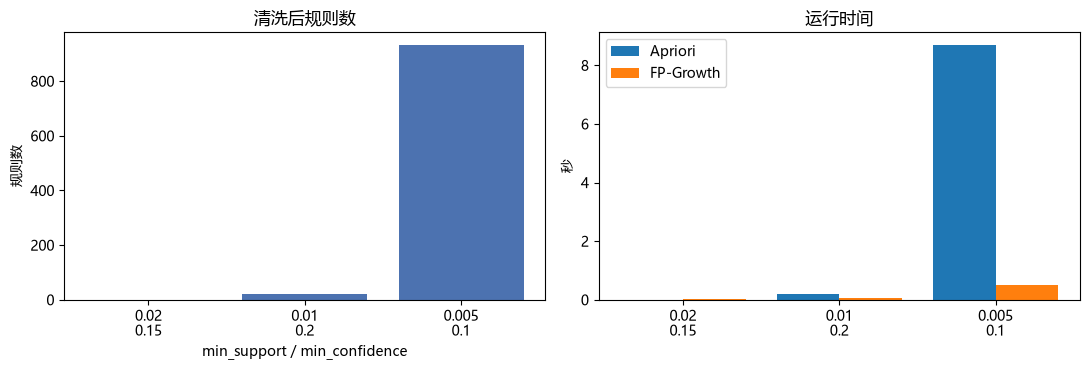

In [2]:
thresholds = pd.read_csv(TABLES / 'rules_thresholds.csv')
display(thresholds)

labels = [f'{s}\n{c}' for s, c in zip(thresholds['min_support'], thresholds['min_confidence'])]
positions = list(range(len(thresholds)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(positions, thresholds['n_rules_dedup'], color='#4c72b0')
axes[0].set_xticks(positions, labels)
axes[0].set_title('清洗后规则数')
axes[0].set_xlabel('min_support / min_confidence')
axes[0].set_ylabel('规则数')
axes[1].bar([p - 0.2 for p in positions], thresholds['apriori_seconds'], width=0.4, label='Apriori')
axes[1].bar([p + 0.2 for p in positions], thresholds['fpgrowth_seconds'], width=0.4, label='FP-Growth')
axes[1].set_xticks(positions, labels)
axes[1].set_title('运行时间')
axes[1].set_ylabel('秒')
axes[1].legend()
plt.tight_layout()
plt.show()

In [3]:
top = pd.read_csv(TABLES / 'rules_top.csv')
columns = ['rank', 'antecedent_titles', 'consequent_title', 'support', 'confidence', 'lift', 'count']
display(top[columns].head(15).round({'support': 4, 'confidence': 4, 'lift': 1}))

,rank,antecedent_titles,consequent_title,support,confidence,lift,count
0,1,Euro Trip II - Hidden Object Game [Download],House Season - Hidden Objects Game [Download],0.0058,0.9016,134.1,110
1,2,Renovation - Hidden Object Game [Download],Euro Trip II - Hidden Object Game [Download],0.0053,0.8559,133.5,101
2,3,Renovation - Hidden Object Game [Download],House Season - Hidden Objects Game [Download],0.0053,0.8559,127.3,101
3,4,House Season - Hidden Objects Game [Download],Picnic Spot - Hidden Object Game [Download],0.0065,0.9688,126.3,124
4,5,Euro Trip II - Hidden Object Game [Download],Picnic Spot - Hidden Object Game [Download],0.0062,0.9672,126.1,118
5,6,Renovation - Hidden Object Game [Download],Crimson China - Hidden Object Game [Download],0.0059,0.9492,122.9,112
6,7,Renovation - Hidden Object Game [Download],Picnic Spot - Hidden Object Game [Download],0.0058,0.9407,122.6,111
7,8,Euro Trip II - Hidden Object Game [Download],Crimson China - Hidden Object Game [Download],0.0060,0.9426,122.0,115
8,9,Euro Trip II - Hidden Object Game [Download],The Cheese Hunter - Hidden Objects Game [Downl...,0.0050,0.7869,121.8,96
9,10,Travel Pack - 3 in 1 - Hidden Object Game [Dow...,Crimson China - Hidden Object Game [Download],0.0054,0.9358,121.2,102


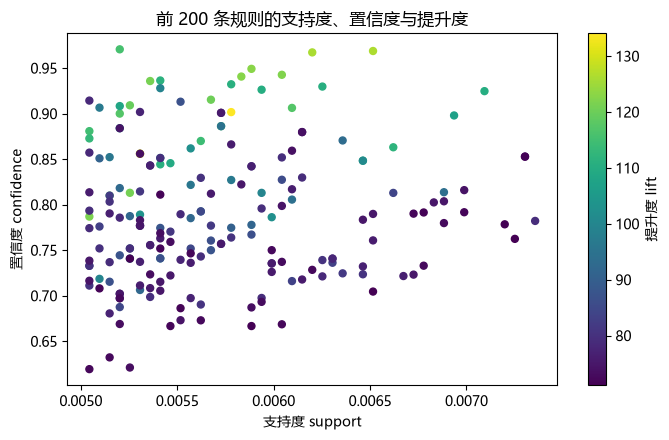

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
scatter = ax.scatter(top['support'], top['confidence'], c=top['lift'], cmap='viridis', s=25)
ax.set_xlabel('支持度 support')
ax.set_ylabel('置信度 confidence')
ax.set_title('前 200 条规则的支持度、置信度与提升度')
fig.colorbar(scatter, label='提升度 lift')
plt.tight_layout()
plt.show()

## 业务解读

1. **系列续作互补**：`Mario Party 2 → Mario Party`（support 0.51%，confidence 81.0%，lift 115.9）、`Super Monkey Ball → Super Monkey Ball 2`（0.51%，71.9%，99.8）。买了前作的玩家会补续作，推荐位按系列排布。
2. **同平台系列粉丝集中**：`Pokémon XD: Gale of Darkness → Pokémon Colosseum`（0.56%，82.2%，95.9，均为 GameCube）、`Shin Megami Tensei Digital Devil Saga 2 → Digital Devil Saga`（0.69%，81.4%，93.9，均为 PS2）。
3. **掌机/复古平台成团**：`FINAL FANTASY X|X-2 HD Remaster → World of Final Fantasy`（0.61%，80.6%，94.1，均为 PS Vita），说明该平台的玩家群体小但重合度高。
4. **下载版隐藏物品游戏形成封闭团**：`Euro Trip II → House Season`（0.58%，90.2%，134.1）。前 200 条规则中 41 条来自这个系列，support 都在 0.5% 左右，lift 却超过 100，属于同一发行商批量填写的推荐位，不是跨品类真实购买。
5. **阈值一降，规则暴涨**：support 0.02 时 0 条，0.01 时 21 条（去重后），0.005 时 932 条。说明强规则只存在于小众团，主流商品对的共购强度达不到高支持度。

## 已知限制

- `also_buy` 是亚马逊推荐位列表，不是收银小票；support 表示“推荐列表共同出现的比例”，不能说明真实联合购买率。
- 篮长上限截断为 50（原始数据最大 100，中位 13），截断会轻微压低大篮中商品的 support。
- 规则经 `lift > 1` 过滤并做对称去重（`A→B` 与 `B→A` 保留置信度高的一条），1,855 条降到 932 条。
- 频繁商品只有 755 个，长尾商品没有规则；结论只覆盖头部商品。
- support 0.5% 约等于 100 个购物篮，不能解读为“大多数玩家”。
